# ПЗ-2. Трансформеры: attention, эмбеддинги, генерация

В этой практической работе рассмотрим архитектуру Transformer на примере задачи генерации текста.
На новостных текстах последовательно разберем устройство модели, ее обучение, стратегии генерации и способы ускорения вычислений:

- positional encoding и механизм scaled dot-product attention с причинной (causal) маской;
- Multi-Head Attention, FeedForward и DecoderBlock как составные части модели;
- сборка языковой модели TransformerLM, ее обучение и сравнение с LSTM по loss и perplexity с отслеживанием экспериментов в MLflow;
- генерация текста с помощью предобученной модели: greedy-декодирование, temperature, top-k и top-p (nucleus) sampling;
- визуализация карт внимания, эффект attention sink и разреженность внимания;
- разреженное внимание со скользящим окном (sliding window attention) и сравнение с полным вниманием по скорости и качеству.

Главная цель практики: понять, как устроен механизм внимания, чем трансформер отличается от рекуррентных моделей, как выбор способа декодирования влияет на сгенерированный текст и какой ценой достигается ускорение на длинных последовательностях.

Установка зависимостей и импорты

In [1]:
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.pre_tokenizers import ByteLevel
from tokenizers.decoders import ByteLevel as ByteLevelDecoder
from tokenizers.trainers import BpeTrainer
from datasets import load_dataset
import matplotlib.pyplot as plt
from mlflow.tracking import MlflowClient
import os
import pickle
import gc

/media/project/susu_course/neural_gen/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#!pip install -q datasets mlflow tokenizers sacrebleu rouge-score scikit-learn

In [3]:
import re, random, math

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

import mlflow
from mlflow.tracking import MlflowClient

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# DEVICE = 'cpu'
print("Device:", DEVICE)

Device: cuda


### Настройка MLflow

Как и в ПЗ-1, используем локальный `mlflow.db`. Отдельный эксперимент для этой практики, чтобы не путать с ПЗ-1 - но при желании можно логировать в тот же трекинг-сервер и сравнивать runs между практиками напрямую.

In [4]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("pz2_transformers")
client = MlflowClient()

### Данные и токенизация

Для сравнимости с ПЗ-1 используем **тот же корпус** (`IlyaGusev/gazeta`)


In [5]:
RAW_ARTICLES_LIMIT = 1000  # как в базовом прогоне ПЗ-1; для финальных экспериментов увеличить


def load_corpus(limit=RAW_ARTICLES_LIMIT):
    from datasets import load_dataset
    ds = load_dataset("IlyaGusev/gazeta", split="train", streaming=True)
    texts = []
    for i, row in enumerate(ds):
        if i >= limit:
            break
        texts.append(row["text"])
    return texts


def clean_text(text: str) -> str:
    text = text.replace("\xa0", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()


texts = [clean_text(t) for t in load_corpus()]
print(f"Загружено статей: {len(texts)}")

Загружено статей: 1000


In [6]:
class BaseTokenizer:
    """Базовый интерфейс токенизатора для работы с текстовыми данными."""

    pad_id = 0

    def encode(self, text: str) -> list[int]:
        """Преобразует текст в последовательность идентификаторов токенов.

        Args:
            text: Исходный текст для токенизации.

        Returns:
            Последовательность идентификаторов токенов.

        """
        raise NotImplementedError

    def decode(self, ids: list[int]) -> str:
        """Восстанавливает текст из последовательности идентификаторов.

        Args:
            ids: Последовательность идентификаторов токенов.

        Returns:
            Восстановленный текст.

        """
        raise NotImplementedError

    @property
    def vocab_size(self) -> int:
        """Возвращает размер словаря токенизатора.

        Returns:
            Количество токенов в словаре.
        """
        raise NotImplementedError

    def get_token_count(self, text: str) -> int:
        """Возвращает количество токенов в переданном тексте.

        Args:
            text: Исходный текст.

        Returns:
            Количество токенов.
        """
        return len(self.encode(text))

In [7]:
class BPETokenizer(BaseTokenizer):
    def __init__(self, docs, vocab_size=16000):
        self.tokenizer = Tokenizer(BPE(unk_token="<unk>"))
        self.tokenizer.pre_tokenizer = ByteLevel(add_prefix_space=False)
        self.tokenizer.decoder = ByteLevelDecoder()

        trainer = BpeTrainer(vocab_size=vocab_size, special_tokens=["<pad>", "<unk>", "<eos>", ])
        self.tokenizer.train_from_iterator(docs, trainer=trainer)

        self.stoi = self.tokenizer.get_vocab()
        self.itos = {idx: token for token, idx in self.stoi.items()}

        self.pad_id = self.stoi["<pad>"]
        self.unk_id = self.stoi["<unk>"]
        self.eos_id = self.stoi["<eos>"]

    @property
    def vocab_size(self):
        return self.tokenizer.get_vocab_size()

    def encode(self, text):
        return self.tokenizer.encode(text).ids

    def decode(self, ids):
        return self.tokenizer.decode(ids)

    def tokenize(self, text):
        return self.tokenizer.encode(text).tokens


tokenizer = BPETokenizer(docs=texts, vocab_size=12000)


### Формирование датасета

`SlidingWindowDataset` переиспользуется без изменений из ПЗ-1 (интерфейс тот же: `input`/`target`, сдвиг на 1 токен, скользящее окно с `stride`, разделитель между статьями).

In [8]:
# TODO: вставить класс SlidingWindowDataset из ПЗ-1 без изменений
class SlidingWindowDataset(Dataset):
    def __init__(self, docs, tokenizer, seq_len=128, stride=64):
        raise NotImplementedError("Скопируйте реализацию из ПЗ-1")



## Блок 1. Трансформер

### 1.1 Общая архитектура

Как и в ПЗ-1 (`BaseLanguageModel`), общая идея - `Embedding → обработка контекста → Linear → logits`. Разница в том, как обрабатывается контекст: вместо рекуррентности (RNN/LSTM передают hidden state по шагам) трансформер обрабатывает всю последовательность сразу через self-attention. В результате каждый токен "смотрит" на все предыдущие токены напрямую, без промежуточных шагов.

### 1.2 Positional Encoding

Механизм attention сам по себе не учитывает порядок токенов. Он работает с набором эмбеддингов и сравнивает их между собой, но без дополнительной информации не знает, какой токен стоит первым, вторым или третьим.

«собака кусает человека» и «человек кусает собаку» для него один и тот же набор токенов. Для задачи языкового моделирования этого недостаточно.
Чтобы передать модели информацию о порядке, к каждому токену добавляется позиционное кодирование (Positional Encoding, PE).

В оригинальном Transformer из статьи Attention Is All You Need используется фиксированное синусоидальное позиционное кодирование:

$$PE_{(pos, 2i)} = \sin(pos / 10000^{2i/d}) \qquad PE_{(pos, 2i+1)} = \cos(pos / 10000^{2i/d})$$

где $pos$ - позиция токена в последовательности, $i$ - номер пары координат позиционного вектора, $d$ - размерность эмбеддинга.

Итоговый входной вектор получается сложением обычного эмбеддинга токена и его позиционного кодирования:

$$
x_{pos} = E_{token} + PE_{pos}
$$

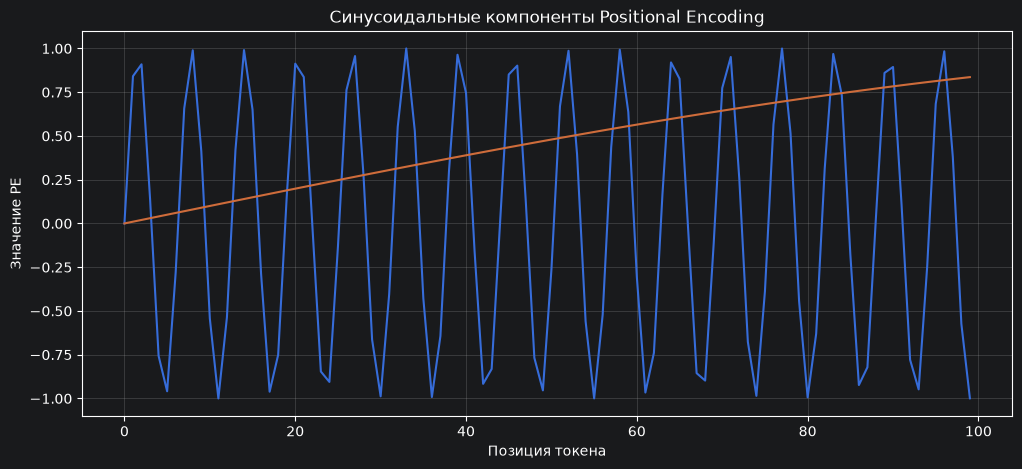

In [9]:
import numpy as np
import matplotlib.pyplot as plt

positions = np.arange(100)
d = 4

plt.figure(figsize=(12, 5))

for i in range(d // 2):
    pe = np.sin(positions / (10000 ** (2 * i / d)))
    plt.plot(positions, pe)

plt.title("Синусоидальные компоненты Positional Encoding")
plt.xlabel("Позиция токена")
plt.ylabel("Значение PE")
plt.grid(alpha=0.3)

plt.show()

В этом примере мы специально взяли небольшую размерность эмбеддинга: $ d = 4 $
Это означает, что позиционный вектор будет иметь 4 координаты:$ PE_{pos} = [PE_0, PE_1, PE_2, PE_3] $

Всего: $\frac{d}{2} = \frac{4}{2}=2$ разных частоты (Поскольку `sin` и `cos` используются попарно).

Для `i = 0` строится первая синусоида:
$
\sin\left(\frac{pos}{10000^0}\right)
=
\sin(pos)
$

Для `i = 1` строится вторая синусоида:
$
\sin\left(\frac{pos}{10000^{2/4}}\right)
=
\sin\left(\frac{pos}{100}\right)
$

Поэтому на графике мы видим две волны с разной частотой:

```text
i = 0 → sin(pos)       → меняется быстро
i = 1 → sin(pos / 100) → меняется медленно
```

Это и есть основная идея positional encoding: одна и та же позиция кодируется одновременно несколькими волнами разной частоты.

Например, для некоторой позиции `pos` мы получаем не одно число, а комбинацию значений:
$
PE_{pos} =
[
\sin(pos),
\cos(pos),
\sin(pos/100),
\cos(pos/100)
]
$

В итоге позиция `10` и позиция `20` имеют разные комбинации значений. Более того, благодаря использованию нескольких частот модель может различать как близкие, так и более далекие позиции.

> Важно: в этом графике мы рисуем только `sin`-компоненты, поэтому видим 2 линии. В настоящем positional encoding для `d = 4` есть 4 координаты: 2 синусоидальные и 2 косинусоидальные.


In [10]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 2048):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

### 1.3 Scaled Dot-Product Attention

На предыдущих этапах мы получили представления токенов, содержащие как информацию о самом токене, так и информацию о его позиции благодаря positional encoding. Теперь нам нужен механизм, который позволит модели определить: на какие токены при обработке текущего токена стоит обратить больше внимания? Именно эту задачу решает механизм Attention.

Вспомним из лекции: интуитивно, для каждого токена модель формирует три представления.

Query ($Q$) - что текущий токен «ищет» в других токенах;

Key ($K$) - какая информация есть у каждого токена, по которой его можно сопоставить с запросом;

Value ($V$) - сама информация, которую нужно получить от выбранных токенов.

Attention сначала сравнивает каждый `Query` с каждым `Key`. Чем больше их скалярное произведение, тем сильнее текущий токен должен обратить внимание на соответствующий токен.
Используем стандартный Scaled Dot-Product Attention:
$$
\text{Attention}(Q,K,V)
=
\text{softmax}
\left(
\frac{QK^T}{\sqrt{d_k}}
+
\text{mask}
\right)V
$$

Разберем вычисление по шагам.
1. Считаем сходство между Query и Key в результате получаем матрицу оценок внимания, в которой каждая строка соответствует текущему токену, а каждый столбец токену, на который он может обратить внимание.
$$
QK^T
$$



2. При большой размерности $d_k$ скалярные произведения могут становиться слишком большими по модулю. Это приводит к тому, что `softmax` становится слишком «резким»: один вес приближается к 1, остальные - к 0, из-за чего обучение может становиться нестабильным. Деление на $\sqrt{d_k}$ масштабирует значения и делает последующий `softmax` более стабильным.
$$
\frac{QK^T}{\sqrt{d_k}}
$$



3. Для обычного attention можно разрешить токенам смотреть на всю последовательность. Но при causal attention, который используется при авторегрессивной генерации текста, токен не должен видеть будущее.
Поэтому перед `softmax` в запрещенные позиции добавляется $-\infty$:
$$
\text{score}_{ij} =
\begin{cases}
\text{score}_{ij}, & j \leq i \\
-\infty, & j > i
\end{cases}
$$


4. Применяем softmax и получаем веса внимания.

$$
A =
\text{softmax}
\left(
\frac{QK^T}{\sqrt{d_k}}+\text{mask}
\right)
$$


5. Веса внимания используются для взвешенного суммирования `Value`:

$$
\text{Output}=AV
$$


In [11]:
def scaled_dot_product_attention(Q: torch.Tensor, K: torch.Tensor, V: torch.Tensor,
                                 mask: torch.Tensor = None):
    """Считает scaled dot-product attention независимо для каждой головы параллельно.

    Args:
        Q: Запросы, тензор формы (batch, n_heads, seq_len, d_k).
        K: Ключи, тензор формы (batch, n_heads, seq_len, d_k).
        V: Значения, тензор формы (batch, n_heads, seq_len, d_k).

        Смысл измерений:
            batch     -- число последовательностей в батче;
            n_heads   -- число голов внимания;
            seq_len   -- число токенов в последовательности;
            d_k       -- размерность вектора одной головы (d_model // n_heads).

        mask: Необязательная булева маска, транслируемая к форме
            (batch, n_heads, seq_len, seq_len). Позиции, где mask == True,
            запрещены: их скоры заменяются на -inf до softmax, поэтому вес
            внимания к ним равен 0. Если None, внимание считается по всем
            позициям.

    Returns:
        tuple[torch.Tensor, torch.Tensor]:
            output: Результат внимания, форма (batch, n_heads, seq_len, d_k).
            attn_weights: Веса внимания после softmax, форма
                (batch, n_heads, seq_len, seq_len). Элемент [b, h, i, j] --
                доля внимания, которую токен i уделяет токену j. Каждая строка
                (по последней оси) суммируется в 1.
    """
    d_k = Q.size(-1)
    scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)

    if mask is not None:
        scores = scores.masked_fill(mask, float("-inf"))

    attn_weights = F.softmax(scores, dim=-1)
    output = torch.matmul(attn_weights, V)
    return output, attn_weights


def causal_mask(seq_len: int, device=None) -> torch.Tensor:
    """Маска, которая не дает токену заглядывать вперед.

    Каждый токен видит себя и все, что было до него, но не то, что идет после.
    Возвращает тензор (1, 1, seq_len, seq_len), где True значит «смотреть нельзя».
    """
    mask = torch.triu(torch.ones(seq_len, seq_len, dtype=torch.bool, device=device), diagonal=1)
    return mask.unsqueeze(0).unsqueeze(0)

### Multi-Head Attention

Одна голова внимания дает один набор весов, по которому он решает, на какие токены смотреть. Но токены связаны друг с другом по-разному сразу. Например, одна связь может быть синтаксической, другая смысловой. Чтобы модель могла учитывать несколько таких связей одновременно, внимание делают многоголовым: несколько голов параллельно смотрят на одну и ту же последовательность, и у каждой свои обучаемые проекции $Q$, $K$ и $V$.

Формально:

$$
\text{head}_h = \text{Attention}(QW^Q_h,\ KW^K_h,\ VW^V_h), \qquad
\text{MultiHead}(x) = \text{Concat}(\text{head}_1, \dots, \text{head}_H)\, W^O
$$

На практике $W^Q_h$ всех голов объединяют в один линейный слой размера $d_{model} \times d_{model}$, а затем делят результат на $H$ частей по $d_k = d_{model} / H$ каналов. Вычислений при этом не больше, чем у одной головы размера $d_{model}$: размерность не растет, а делится между головами.

В классе уже есть все необходимое:

- `q_proj`, `k_proj`, `v_proj` - линейные слои, которые строят $Q$, $K$ и $V$ сразу для всех голов;
- `_split_heads` переводит тензор `(batch, seq_len, d_model)` в `(batch, n_heads, seq_len, d_k)`, то есть выделяет головы в отдельное измерение;
- `_merge_heads` делает обратное преобразование;
- `out_proj` смешивает информацию, собранную разными головами.


In [12]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.d_k = d_model // n_heads
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)

    def _split_heads(self, x):
        b, t, d = x.shape
        return x.view(b, t, self.n_heads, self.d_k).transpose(1, 2)  # (b, h, t, d_k)

    def _merge_heads(self, x):
        b, h, t, d_k = x.shape
        return x.transpose(1, 2).contiguous().view(b, t, h * d_k)

    def forward(self, x, mask=None):
        Q = self._split_heads(self.q_proj(x))
        K = self._split_heads(self.k_proj(x))
        V = self._split_heads(self.v_proj(x))
        out, attn_weights = scaled_dot_product_attention(Q, K, V, mask=mask)
        out = self.out_proj(self._merge_heads(out))
        return out, attn_weights

### Decoder Block

Attention позволяет токенам обмениваться информацией друг с другом, но этого недостаточно. После обмена каждому токену нужно еще «обдумать» то, что он собрал. Для этого после attention идет небольшой обучаемый слой, который обрабатывает каждый токен независимо: он не смешивает токены между собой, а меняет представление каждого из них. Получается разделение ролей:

- Attention смотрит на другие токены и собирает информацию из контекста;
- FeedForward перерабатывает собранное внутри каждого токена по отдельности.

### FeedForward

Это две линейные проекции с нелинейностью между ними. Сначала представление токена расширяется с `d_model` до `d_ff` (обычно в 4 раза больше), затем применяется `GELU`, и результат сжимается обратно до `d_model`. Расширение дает модели больше «места» для вычислений. Нелинейность не позволяет двум линейным слоям схлопнуться в один.

### DecoderBlock

Блок собирает attention и FeedForward в один слой трансформера.

Чтобы глубокая сеть стабильно обучалась, блок использует три приема.

- Residual-связь. Результат подслоя не заменяет вход, а прибавляется к нему. Информация и градиенты проходят через слои напрямую, а каждый подслой лишь добавляет к представлению токена что-то новое.
- LayerNorm перед подслоем (pre-LN). Нормализуется то, что идет *внутрь* attention и FeedForward, а к исходному представлению прибавляется уже результат подслоя. Так масштаб значений не разъезжается от слоя к слою.
- Dropout. Применяется к выходу подслоя перед сложением и нужен для регуляризации во время обучения.

В конструкторе уже созданы все нужные части: `ln1`, `attn`, `ln2`, `ff` и `dropout`.

Метод должен вернуть пару `(x, attn_weights)`: новое представление токенов формы `(batch, seq_len, d_model)` и веса внимания, которые вернул `attn`. Они понадобятся позже для визуализации. Форма `x` на выходе совпадает с формой на входе, поэтому блоки можно ставить друг за другом.

In [13]:
class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))

    def forward(self, x):
        return self.net(x)


class DecoderBlock(nn.Module):
    def __init__(self, d_model: int, n_heads: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads)
        self.ln2 = nn.LayerNorm(d_model)
        self.ff = FeedForward(d_model, d_ff)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        attn_out, attn_weights = self.attn(self.ln1(x), mask=mask)
        x = x + self.dropout(attn_out)
        x = x + self.dropout(self.ff(self.ln2(x)))
        return x, attn_weights

### 1.5 Модель целиком


Теперь соберем из готовых частей целую модель.
Путь данных через модель

1. Номера токенов преобразуются в векторы через `embedding`. К ним добавляется информация о позиции (`pos_encoding`).
2. Векторы проходят через `n_layers` блоков. С каждым блоком представление токена все сильнее впитывает контекст.
3. Финальная нормализация. После последнего блока применяется `ln_f`.
4. Линейный слой `head` переводит каждый вектор в `vocab_size` чисел, то есть в оценки (логиты) для каждого токена словаря. Чем выше значение, тем вероятнее, что именно этот токен идет следующим.

Дополнительные режимы `forward`. Они понадобятся в следующих разделах.

- `return_attn=True` собирает веса внимания из каждого блока в список (по одному элементу на блок). Их мы будем использовать для визуализации.


In [30]:
class TransformerLM(nn.Module):
    def __init__(self, tokenizer, d_model: int = 256, n_heads: int = 4,
                 n_layers: int = 4, d_ff: int = 1024, max_len: int = 512, dropout: float = 0.1):
        super().__init__()
        self.tokenizer = tokenizer
        self.context_len = max_len
        self.embedding = nn.Embedding(tokenizer.vocab_size, d_model)
        self.pos_encoding = PositionalEncoding(d_model, max_len=max_len)
        self.blocks = nn.ModuleList([
            DecoderBlock(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)
        ])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, tokenizer.vocab_size)

    def forward(self, x, return_attn=False, return_hidden_at=None, **sampling_kwargs):
        """
        x: (batch, seq_len) token ids
        return_hidden_at: индекс decoder-блока, после которого вернуть hidden state
                           (пригодится в разделе про эмбеддинги)
        """
        mask = causal_mask(x.size(1), device=x.device)
        h = self.pos_encoding(self.embedding(x))
        attn_maps = []
        hidden_snapshot = None
        for i, block in enumerate(self.blocks):
            h, attn_w = block(h, mask=mask)
            if return_attn:
                attn_maps.append(attn_w)
            if return_hidden_at is not None and i == return_hidden_at:
                hidden_snapshot = h.clone()
        logits = self.head(self.ln_f(h))
        if return_attn or return_hidden_at is not None:
            return logits, attn_maps, hidden_snapshot
        return logits, None

In [31]:
def train_one_epoch(model, loader, optimizer, criterion):
    """Одна эпоха обучения модели

    Args:
        model: Обучаемая модель
        loader: DataLoader с обучающими данными
        optimizer: Оптимизатор для обновления параметров модели
        criterion: Функция потерь

    Returns:
        Средний loss за эпоху
    """
    model.train()
    total_loss, n_batches = 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        logits, _ = model(x)
        loss = criterion(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        n_batches += 1
    return total_loss / max(n_batches, 1)


@torch.no_grad()
def evaluate(model, loader, criterion):
    """Оценивает модель на данных без обновления параметров

    Args:
        model: Обучаемая модель
        loader: DataLoader с данными для оценки
        criterion: Функция потерь

    Returns:
        Средний loss на данных
    """
    model.eval()
    device = next(model.parameters()).device
    total_loss, n_batches = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits, _ = model(x)
        loss = criterion(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
        total_loss += loss.item()
        n_batches += 1
    return total_loss / max(n_batches, 1)


### 1.6 Обучение

Training loop - тот же принцип, что в ПЗ-1: `CrossEntropyLoss` на next-token prediction, логирование `train_loss`/`val_loss`/`perplexity`/времени эпохи в MLflow. Переиспользуем функции `train_one_epoch`, `evaluate`, `compute_perplexity`, `train_model` из ПЗ-1 практически без изменений - модель просто вызывается как `model(input_batch)` без hidden state.

In [32]:
def compute_perplexity(loss):
    return math.exp(min(loss, 20))  # ограничение, чтобы не улетало в inf на старте обучения

In [33]:
def train_model(model, train_loader, val_loader, test_loader, epochs=60, lr=1e-3, params=None):
    """Обучает модель, оценивает ее качество и сохраняет результаты эксперимента
    Args: 
        model: Модель для обучения
        train_loader: DataLoader с обучающими данными
        val_loader: DataLoader с валидационными данными
        test_loader: DataLoader с тестовыми данными
        epochs: Количество эпох обучения
        lr: Начальная скорость обучения
        params: Дополнительные параметры эксперимента для MLflow
    Returns: Обученная модель и история значений метрик
    """
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)
    criterion = nn.CrossEntropyLoss(ignore_index=model.tokenizer.pad_id)
    history = {"train_loss": [], "val_loss": [], "val_ppl": []}
    best_val_loss = float("inf")
    best_state = None

    with mlflow.start_run():
        if params:
            mlflow.log_params(params)
        mlflow.log_param("n_parameters", sum(p.numel() for p in model.parameters()))
        run_name = mlflow.active_run().info.run_name
        for epoch in tqdm(range(epochs)):
            train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
            val_loss = evaluate(model, val_loader, criterion)
            val_ppl = compute_perplexity(val_loss)
            scheduler.step(val_loss)

            history["train_loss"].append(train_loss)
            history["val_loss"].append(val_loss)
            history["val_ppl"].append(val_ppl)
            mlflow.log_metric("train_loss", train_loss, step=epoch)
            mlflow.log_metric("val_loss", val_loss, step=epoch)
            mlflow.log_metric("val_perplexity", val_ppl, step=epoch)
            mlflow.log_metric("lr", optimizer.param_groups[0]["lr"], step=epoch)

            print(f"[{run_name}] epoch {epoch + 1}/{epochs} \n"
                  f"params: {params} \n"
                  f"train_loss={train_loss:.3f} val_loss={val_loss:.3f} val_ppl={val_ppl:.1f} \n"
                  f"lr={optimizer.param_groups[0]['lr']:.2e}")

            if val_loss < best_val_loss - 1e-4:
                best_val_loss = val_loss
                best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        if best_state is not None:
            model.load_state_dict(best_state)  # откатываемся на лучший чекпоинт
            test_loss = evaluate(model, test_loader, criterion)
            test_ppl = compute_perplexity(test_loss)
            mlflow.log_metric("test_loss", test_loss)
            mlflow.log_metric("test_ppl", test_ppl)
            ckpt_path = f"{run_name}.pt"
            tokenizer_path = f"{run_name}_tokenizer.pkl"
            with open(tokenizer_path, "wb") as f:
                pickle.dump(tokenizer, f)
            torch.save(best_state, ckpt_path)
            mlflow.log_artifact(ckpt_path)
            mlflow.log_artifact(tokenizer_path)
            os.remove(ckpt_path)
            os.remove(tokenizer_path)
            mlflow.log_metric("best_val_loss", best_val_loss)
            mlflow.log_metric("best_val_ppl", compute_perplexity(best_val_loss))

    model.to("cpu")
    del optimizer
    gc.collect()
    torch.cuda.empty_cache()
    mlflow.end_run()
    return model, history

In [34]:
def make_loaders(train_docs, val_docs, test_docs, tokenizer, seq_len, batch_size=64, stride=None):
    """Создает DataLoader для обучающей, валидационной и тестовой выборок.

    Args:
        train_docs: Обучающие документы.
        val_docs: Валидационные документы.
        test_docs: Тестовые документы.
        tokenizer: Токенизатор.
        seq_len: Длина входной последовательности.
        batch_size: Размер батча.
        stride: Шаг скользящего окна.

    Returns:
        Кортеж из трех DataLoader: для обучения, валидации и тестирования.
    """
    train_ds = SlidingWindowDataset(train_docs, tokenizer, seq_len, stride)
    val_ds = SlidingWindowDataset(val_docs, tokenizer, seq_len, stride)
    test_ds = SlidingWindowDataset(test_docs, tokenizer, seq_len, stride)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, drop_last=True)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, drop_last=True)
    return train_loader, val_loader, test_loader

In [35]:
# Поэтому сначала перемешиваем целые статьи
random.shuffle(texts)

#А затем распределяем документы между тремя выборками
n = len(texts)
n_train = int(n * 0.5)
n_val = int(n * 0.25)
train_docs = texts[:n_train]
val_docs = texts[n_train:n_train + n_val]
test_docs = texts[n_train + n_val:]
print(f"train={len(train_docs)}  val={len(val_docs)}  test={len(test_docs)}")


train=500  val=250  test=250


In [20]:
tokenizer = BPETokenizer(docs=texts, vocab_size=8000)


## Обучение трансформера и сравнение с LSTM

**Задание.** Обучите одну модель-трансформер (`TransformerLM`) и сравните ее с LSTM-моделью, обученной **на том же токенизаторе**.

1. Для LSTM можно взять результаты из предыдущей работы (ПЗ-1), если модель и история обучения сохранились. Если нет, обучите LSTM заново: перенесите код модели и цикла обучения из ПЗ-1 в этот ноутбук.
2. Условия обучения обеих моделей должны быть сопоставимы: один и тот же токенизатор, длина последовательности (`TRAIN_SEQ_LEN`), разбиение на train/val/test, число эпох. Это нужно, чтобы различие в метриках объяснялось архитектурой, а не настройками.
3. Логируйте обучение в **MLflow**: train loss, val loss, val perplexity по эпохам, а также гиперпараметры запуска.
4. Постройте графики по логам MLflow: кривые val loss и val perplexity для трансформера и LSTM на одной оси.
5. Сделайте выводы: какая модель достигла меньшей перплексии, как быстро шла сходимость, есть ли признаки переобучения, сколько параметров у каждой модели.

В ячейке ниже задана сетка гиперпараметров. Подставьте свои диапазоны; для единственного запуска оставьте по одному значению в каждом списке.

In [21]:
import itertools
import gc
import torch

TRAIN_SEQ_LEN = 128
BATCH_SIZE = 16
EPOCHS = 10
tokenizer_name = 'bre'
cell_type = 'Transformer'

param_grid = {
    "lr": [3e-4],
    "emb_dim": [128],
    "hidden_dim": [1024],
    "n_layers": [3],
    "n_heads": [6],
}

trained_models = {}
results = []
keys = list(param_grid.keys())
combinations = list(itertools.product(*param_grid.values()))
print(f"Всего конфигов: {len(combinations)}")

for i, values in enumerate(combinations):
    cfg = dict(zip(keys, values))
    print(f"\n=== [{i + 1}/{len(combinations)}] {cfg} ===")

    train_loader, val_loader, test_loader = make_loaders(
        train_docs, val_docs, test_docs,
        tokenizer, TRAIN_SEQ_LEN, batch_size=BATCH_SIZE,
    )

    model = TransformerLM(
        d_model=cfg["emb_dim"],
        n_layers=cfg["n_layers"],
        n_heads=cfg["n_heads"],
        d_ff=cfg["hidden_dim"],
        max_len=TRAIN_SEQ_LEN,
        tokenizer=tokenizer,
    )

    model, history = train_model(
        model, train_loader, val_loader, test_loader,
        epochs=EPOCHS,
        lr=cfg["lr"],
        params={
            "cell_type": cell_type,
            "train_seq_len": TRAIN_SEQ_LEN,
            "emb_dim": cfg["emb_dim"],
            "epochs": EPOCHS,
            "hidden_dim": cfg["hidden_dim"],
            "num_layers": cfg["n_layers"],
            "n_heads": cfg["n_heads"],
            "n_train": n_train,
            "tokenizer": tokenizer_name,
        },
    )

    run_name = f"lr{cfg['lr']}_emb{cfg['emb_dim']}_hid{cfg['hidden_dim']}_L{cfg['n_layers']}"
    trained_models[run_name] = model
    results.append({**cfg, "val_ppl": history["val_ppl"][-1]})

    del train_loader, val_loader
    gc.collect()
    torch.cuda.empty_cache()

Всего конфигов: 1

=== [1/1] {'lr': 0.0003, 'emb_dim': 128, 'hidden_dim': 1024, 'n_layers': 3, 'n_heads': 6} ===


NotImplementedError: Скопируйте реализацию из ПЗ-1

## Блок 2. Генерация


Обучение достаточно большого трансформера на полном корпусе новостей требует значительных вычислительных ресурсов, поэтому для этого блока модель вам будет выдана в готовом виде. В современной практике предобучение крупных моделей выполняется ограниченным числом организаций. Большинство прикладных задач решается с помощью готовых моделей, которые используются напрямую или адаптируются (дообучение, подбор параметров генерации, использование в составе более сложных систем). Обучение моделей с нуля сохраняется для специализированных задач, где подходящих предобученных моделей нет.

По сравнению с моделью из блока 1 предобученная модель:
- обучена на полном корпусе новостей;
- имеет увеличенное контекстное окно: 2048 токенов;
- имеет больше параметров на слой и больше колличество блоков.

Архив `model.tar.xz` содержит три файла:
- `config.json` - гиперпараметры модели;
- `tokenizer.pkl` - сериализованный токенизатор;
- `model.pt` - веса модели (`state_dict`).

Функция `extract_model` читает файлы прямо из архива, без распаковки на диск. Префикс `module.` в именах весов появляется, если модель обучалась через `DataParallel`; функция его удаляет, чтобы имена совпали с именами параметров обычной модели.



In [36]:
import io
import tarfile
import json


def extract_model(path):
    """Загружает модель из архива tar.xz без распаковки на диск.

    Архив содержит `config.json`, `tokenizer.pkl` и `model.pt`.
    Префикс `module.` в именах весов (от `DataParallel`) удаляется.

    Args:
        path: путь к архиву.

    Returns:
        tuple[dict, dict, object]: кортеж из трех элементов:
            - config: словарь гиперпараметров из `config.json`
            - state_dict: веса модели на CPU без префикса `module.`
            - tokenizer: десериализованный токенизатор

    """
    with tarfile.open(path, "r:xz") as tar:
        config = json.load(tar.extractfile("config.json"))
        tokenizer = pickle.load(tar.extractfile("tokenizer.pkl"))
        state_dict = torch.load(io.BytesIO(tar.extractfile("model.pt").read()), map_location="cpu")
        # Если модель обучалась через `DataParallel` на нескольких GPU, имена параметров в
        # `state_dict` начинаются с префикса `module.`. Он удаляется, чтобы имена
        # совпадали с параметрами обычной модели.
        state_dict = {
            k.removeprefix("module."): v
            for k, v in state_dict.items()
        }

    return config, state_dict, tokenizer

In [37]:
config, state_dict, tokenizer = extract_model('model.tar.xz')
config

{'train_seq_len': 2048,
 'emb_dim': 384,
 'hidden_dim': 1536,
 'num_layers': 10,
 'n_heads': 6}

Далее по конфигу создается модель `TransformerLM` с теми же гиперпараметрами, с которыми она обучалась. Затем в нее загружаются обученные веса (`load_state_dict`): без этого шага модель имела бы случайную инициализацию.

In [38]:
model = TransformerLM(
    d_model=int(config["emb_dim"]),
    n_layers=int(config["num_layers"]),
    n_heads=int(config.get("n_heads", 4)),
    d_ff=int(config["hidden_dim"]),
    max_len=int(config['train_seq_len']),
    tokenizer=tokenizer,
)
model
model.load_state_dict(state_dict)
model.eval()

TransformerLM(
  (embedding): Embedding(16000, 384)
  (pos_encoding): PositionalEncoding()
  (blocks): ModuleList(
    (0-9): 10 x DecoderBlock(
      (ln1): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): MultiHeadAttention(
        (q_proj): Linear(in_features=384, out_features=384, bias=True)
        (k_proj): Linear(in_features=384, out_features=384, bias=True)
        (v_proj): Linear(in_features=384, out_features=384, bias=True)
        (out_proj): Linear(in_features=384, out_features=384, bias=True)
      )
      (ln2): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=True)
      (ff): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=384, out_features=1536, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=1536, out_features=384, bias=True)
        )
      )
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (ln_f): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bi

### Шаг модели для трансформера

Класс `TransformerStepper` отвечает за один шаг генерации: получает новый токен и возвращает распределение для следующего. В отличие от рекуррентных сетей, трансформер не хранит скрытое состояние между шагами. Поэтому в роли «состояния» здесь выступает _накопленный контекст_: на каждом шаге к нему добавляется новый токен, и вся последовательность целиком подается в модель. Из выхода берутся логиты только для последней позиции, так как именно они определяют следующий токен.

Контекст ограничен длиной окна модели (`context_len`). При его превышении самые старые токены отбрасываются, и модель «забывает» начало текста. Поскольку на каждом шаге вся последовательность обрабатывается заново, стоимость шага растет с длиной контекста.

In [39]:
class TransformerStepper:
    """Шаг модели для трансформера: на каждом шаге подается весь накопленный контекст."""

    def __init__(self, model: TransformerLM):
        self.model = model

    def init_state(self):
        return None

    def step(self, context, x, **sampling_kwargs):
        """Выполняет один шаг генерации.

        Args:
            context: накопленный контекст формы (1, seq_len) или None на первом шаге.
            x: новый токен формы (1, 1).
            **sampling_kwargs: дополнительные аргументы для вызова модели.

        Returns:
            Кортеж (logits, context): логиты следующего токена формы
            (1, vocab_size) и обновленный контекст, обрезанный до `context_len`.
        """
        context = x if context is None else torch.cat([context, x], dim=1)
        context = context[:, -self.model.context_len:]
        logits, _ = self.model(context, **sampling_kwargs)
        return logits[:, -1, :], context

### 2.1 Greedy-генерация
### Базовый генератор

Класс `LanguageModelGenerator` реализует общий цикл авторегрессионной генерации.

Метод `generate` выполняет следующие действия:
1. Промт кодируется токенизатором и целиком подается в модель. На этом этапе модель обрабатывает весь заданный контекст и возвращает логиты для первого генерируемого токена.
2. В цикле из `max_new_tokens` итераций из логитов выбирается следующий токен, добавляется к последовательности и подается в модель на следующем шаге. В современных реализациях модель может завершить генерацию самостоятельно: если она генерирует специальный токен конца последовательности (EOS, end of sequence), цикл прерывается, не дожидаясь исчерпания лимита `max_new_tokens`. Параметр `max_new_tokens` в этом случае служит лишь верхней границей длины. В нашей реализации проверка на такой токен не предусмотрена, поэтому генерация всегда продолжается ровно `max_new_tokens` шагов.
3. Итоговая последовательность токенов декодируется в текст.

Выбор токена вынесен в отдельный метод `_select_next_token`.
В базовом классе он реализует **жадную генерацию** (greedy decoding): на каждом шаге выбирается токен с максимальным логитом. Такой выбор детерминирован: один и тот же промпт всегда дает один и тот же текст.

In [40]:
class LanguageModelGenerator:
    """Генератор текста на основе обученной языковой модели (жадная генерация).

    Особенности архитектуры (как хранится контекст и как делается шаг)
    инкапсулированы в stepper. Способ выбора токена переопределяется в наследниках.
    """

    def __init__(self, stepper):
        self.stepper = stepper
        self.model = stepper.model
        self.tokenizer = self.model.tokenizer

    def _select_next_token(self, logits, **sampling_kwargs):
        """Жадный выбор токена.
        Args:
            logits: логиты последней позиции, форма (1, vocab_size)

        Returns:
            Тензор выбранного токена, форма (1, 1)
        """
        return torch.argmax(logits, dim=-1, keepdim=True)

    @torch.no_grad()
    def generate(self, prompt, max_new_tokens=50, **sampling_kwargs):
        """Генерирует продолжение текста на основе заданного контекста

        Args:
            prompt: Исходный текст, который используется как контекст/начало генерации
            max_new_tokens: Максимальное количество новых токенов
            **sampling_kwargs: Параметры выбора токена, передаются в _select_next_token

        Returns:
            Исходный prompt с добавленным сгенерированным продолжением
        """
        self.model.eval()
        device = next(self.model.parameters()).device
        tokens = self.tokenizer.encode(prompt)
        x = torch.tensor(tokens, dtype=torch.long, device=device).unsqueeze(0)

        state = self.stepper.init_state()
        logits, state = self.stepper.step(state, x, **sampling_kwargs)

        for _ in range(max_new_tokens):
            next_token = self._select_next_token(logits, **sampling_kwargs)
            tokens.append(next_token.item())
            logits, state = self.stepper.step(state, next_token)

        return self.tokenizer.decode(tokens)

Задание. Сгенерируйте несколько продолжений для одного и того же `prompt`, запустив ячейку несколько раз. Затем измените `prompt` (тема, длина, стиль) и повторите эксперимент. Обратите внимание на следующее:
- совпадают ли результаты при повторных запусках с одним и тем же `prompt`;
- как меняется текст при изменении `prompt`;
- встречаются ли повторы слов и фраз и в какой момент они появляются.

Запишите выводы по увиденному: чем объясняется наблюдаемое поведение и какими свойствами жадной генерации оно обусловлено.

In [41]:
LanguageModelGenerator(TransformerStepper(model)).generate('Два автомобиля выехали')

'Два автомобиля выехали на машине, а затем в Москву. В итоге, по данным ГИБДД, в России было зарегистрировано около 1,5 тыс. транспортных средств, что на 10% больше, чем в 2009 году. В настоящее время в России запрещена часть автомобилей, которые'


### 2.2 Temperature sampling


$$p_i = \frac{\exp(z_i / T)}{\sum_j \exp(z_j / T)}$$

где $z_i$ - логиты, $T$ - температура. Вместо `argmax` сэмплируем следующий токен из этого распределения.

Жадная генерация всегда выбирает самый вероятный токен, поэтому результат детерминирован и склонен к повторам. Сэмплирование устраняет это: токен выбирается случайно, с вероятностями, которые задает модель.
Температура управляет тем, насколько распределение «острое»: логиты делятся на $T$ перед применением softmax.

Температура не меняет порядок токенов по вероятности, меняется только разрыв между ними. Выбор $T$ задает компромисс между связностью и разнообразием текста.

In [42]:
class TemperatureGenerator(LanguageModelGenerator):
    """Генератор с сэмплированием по температуре."""

    def _select_next_token(self, logits, temperature=1.0):
        """Сэмплирование токена из распределения с температурой.

        Args:
            logits: логиты последней позиции, форма (1, vocab_size)
            temperature: температура, T > 0 (T -> 0: ближе к argmax, T > 1: более случайно)

        Returns:
            Тензор выбранного токена, форма (1, 1)
        """
        probs = torch.softmax(logits / temperature, dim=-1)
        # multinomial вместо argmax, потому что токен должен выбираться случайно
        # в соответствии с вероятностями, а не всегда самый вероятный.
        return torch.multinomial(probs, num_samples=1)

    def generate(self, prompt, max_new_tokens=50, temperature=1.0):
        if temperature <= 0:
            raise ValueError("temperature должна быть > 0")
        return super().generate(prompt, max_new_tokens, temperature=temperature)


Задание 2.2. Задание состоит из двух частей.

Часть 1. Генерация при разных температурах.** Сгенерируйте продолжения одного и того же `prompt` при нескольких значениях температуры (например, 0.3, 0.7, 1.0, 1.5), запуская генерацию по несколько раз для каждого значения. Сравните результаты по связности, разнообразию и наличию повторов.

Часть 2. Влияние температуры на распределение. Для одного и того же `prompt` получите логиты модели для следующего токена и сравните, как меняется распределение вероятностей при разных значениях $T$.

1. Выберите несколько значений температуры (например, 0.3, 0.7, 1.0, 1.5).
2. Для каждого $T$ примените softmax к логитам, деленным на $T$.
3. Для каждого $T$ постройте **столбчатую диаграмму вероятностей top-k токенов** (например, $k = 10$). Токены по оси $x$ берите по порядку вероятности при $T = 1$ и используйте одинаковый порядок на всех графиках, чтобы диаграммы были сравнимы. Масштаб оси $y$ также сделайте общим.
4. Сравните диаграммы между собой.

В выводах опишите:
- как меняется вероятность самого вероятного токена при уменьшении и увеличении температуры;
- как меняется суммарная вероятность top-k токенов и что это означает для редких токенов, не попавших в график;
- как наблюдаемые изменения объясняют различия в сгенерированных текстах из части 1.

Дополнительный вопрос. Почему температура ослабляет зацикливание, но не исключает его полностью? Подумайте, что происходит с вероятностью повторяющегося продолжения, когда оно уже встречалось в контексте.

In [45]:
TemperatureGenerator(TransformerStepper(model)).generate('Два автомобиля выехали',temperature=5)


'Два автомобиля выехали ощущение долл супруг линейары признатьруппахов тренером издание Предполагается последствияриидоров большие охран ввозительята специальных км органов официальные брон завед горож неуст Пол того увели кроме 50 ряда сегменте культур политика издел 2021алит купить остальные расчетбольшой восьм Подмосковье занимают президентом бал культуры исследователи'

###  Top-k и top-p (nucleus) sampling

Обычное сэмплирование с температурой выбирает токен из всего словаря.
Даже при умеренной температуре у тысяч маловероятных токенов остается небольшая, но ненулевая вероятность, и суммарно она может быть заметной.
Тогда на каком-то шаге выбирается случайный токен из «хвоста» распределения, и текст теряет связность.
Методы top-k и top-p ограничивают выбор: токены вне заданного набора исключаются, а среди оставшихся выбор делается случайно, с вероятностями, пропорциональными исходным.

Top-k. Остаются $k$ токенов с наибольшими логитами, остальные отбрасываются. Вероятности пересчитываются только по ним. Размер набора фиксирован и не зависит от формы распределения. Это неудобно: если модель почти уверена в одном токене, лишние $k - 1$ кандидатов только добавляют шум, а если распределение широкое, $k$ токенов могут оказаться слишком узким выбором.

Top-p (nucleus sampling). Токены сортируются по убыванию вероятности, и оставляется наименьший набор, суммарная вероятность которого не меньше $p$.

Размер набора динамический: когда модель уверена, в нем один-два токена, когда не уверена, их много.
Поэтому top-p обычно ведет себя устойчивее, чем top-k с фиксированным значением.
Важно, что отсечение хвоста не устраняет зацикливание. Оно убирает редкие случайные токены, но не меняет того, что после уже встречавшегося фрагмента его повтор остается самым вероятным продолжением.

Задание. Сгенерируйте продолжения одного и того же `prompt` с помощью `TopKGenerator` (например, $k = 5, 50$) и `TopPGenerator` (например, $p = 0.5, 0.9$) при фиксированной температуре.
Сравните результаты между собой и с обычным сэмплированием с температурой: оцените связность, разнообразие, наличие повторов.
Запишите выводы о том, чем различаются поведения методов и в каких случаях ограничение набора токенов полезно.


In [46]:
class TopKGenerator(TemperatureGenerator):
    """Сэмплирование среди top-k самых вероятных токенов."""

    def _select_next_token(self, logits, temperature=1.0, top_k=50):
        top_k = min(top_k, logits.size(-1))
        top_values, top_indices = torch.topk(logits, top_k, dim=-1)
        probs = torch.softmax(top_values / temperature, dim=-1)
        choice = torch.multinomial(probs, num_samples=1)
        return top_indices.gather(-1, choice)

    def generate(self, prompt, max_new_tokens=50, temperature=1.0, top_k=50):
        if temperature <= 0:
            raise ValueError("temperature должна быть > 0")
        if top_k < 1:
            raise ValueError("top_k должен быть >= 1")
        return LanguageModelGenerator.generate(
            self, prompt, max_new_tokens, temperature=temperature, top_k=top_k
        )


class TopPGenerator(TemperatureGenerator):
    """Сэмплирование из наименьшего набора токенов с суммарной вероятностью >= top_p."""

    def _select_next_token(self, logits, temperature=1.0, top_p=0.9):
        if temperature <= 0:
            raise ValueError("temperature должна быть > 0")
        if not 0 < top_p <= 1:
            raise ValueError("top_p должен быть в (0, 1]")

        sorted_logits, sorted_indices = torch.sort(logits, descending=True, dim=-1)
        probs = torch.softmax(sorted_logits / temperature, dim=-1)
        cumulative = probs.cumsum(dim=-1)
        # убираем токены, перед которыми накопленная вероятность уже достигла top_p
        # (самый вероятный токен всегда остается)
        probs[(cumulative - probs) >= top_p] = 0.0
        choice = torch.multinomial(probs, num_samples=1)
        return sorted_indices.gather(-1, choice)

    def generate(self, prompt, max_new_tokens=50, temperature=1.0, top_p=0.9):

        return LanguageModelGenerator.generate(
            self, prompt, max_new_tokens, temperature=temperature, top_p=top_p
        )

In [50]:
print(TopKGenerator(TransformerStepper(model)).generate('Два автомобиля выехали',temperature=2, top_k=5))
print(TopPGenerator(TransformerStepper(model)).generate('Два автомобиля выехали',temperature=2, top_p=0.1))



Два автомобиля выехали на машине в автомобиле Toyota, который был на борту. «Водителям машин Toyota Lexand Vision с номерами не справился с управлением на машине. В результате полученных телесных повреждений у него обнаружено не было. В результате ДТП водитель
Два автомобиля выехали на переезд машины и попытались задержать его, поэтому они сехали на безопасное расстояние. Однако у автомобиля была другая машина, в которой оказался «дебил» Mitsubishi и ехал из него на машине. Водитель



## Блок 3. Оптимизация Трансформера


### 3.1 Карты внимания



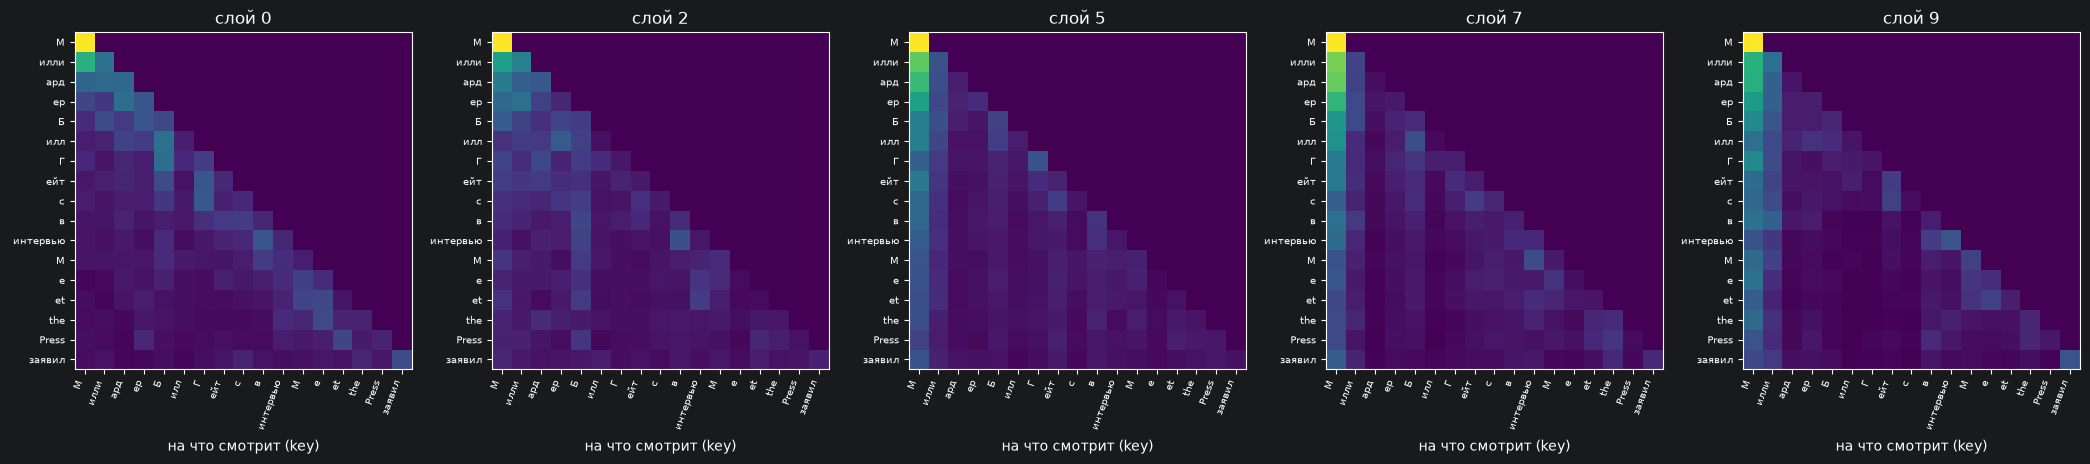

In [51]:

@torch.no_grad()
def plot_attention_maps(model, sentence: str, layers=None, head: int = None):
    """Карты внимания token×token на выбранных слоях. head=None -> среднее по головам."""
    model.eval()
    tokenizer = model.tokenizer
    device = next(model.parameters()).device
    ids = tokenizer.encode(sentence)
    tokens = [tokenizer.decode([t]) for t in ids]
    x = torch.tensor([ids], device=device)
    _, attn_maps, _ = model(x, return_attn=True)
    # print(attn_maps)
    L = len(model.blocks)
    layers = layers or [0, L // 4, L // 2, 3 * L // 4, L - 1]
    atts = []
    fig, axes = plt.subplots(1, len(layers), figsize=(4.2 * len(layers), 4.5))
    for ax, l in zip(np.atleast_1d(axes), layers):
        a = attn_maps[l][0]  # (n_heads, T, T)
        a = a.mean(0) if head is None else a[head]
        atts.append(a)
        ax.imshow(a.cpu().numpy(), cmap="viridis")
        ax.set_xticks(range(len(tokens)))
        ax.set_yticks(range(len(tokens)))
        ax.set_xticklabels(tokens, rotation=70, ha="right", fontsize=7)
        ax.set_yticklabels(tokens, fontsize=7)
        ax.set_title(f"слой {l}" + ("" if head is None else f", голова {head}"))
        ax.set_xlabel("на что смотрит (key)")
    plt.tight_layout()
    plt.show()
    return atts


_ = plot_attention_maps(model,
                        "Миллиардер Билл Гейтс в интервью Meet the Press заявил")


Рассмотрим карты по порядку.
1. Часть матрицы пуста по построению. Модель генерирует текст слева направо, поэтому токен не может смотреть на последующие токены: ненулевые значения расположены только на диагонали и под ней (маска причинности). Примерно половина пар токенов заведомо не участвует в работе механизма.
2. Чем глубже слой, тем неравномернее внимание. На ранних слоях веса распределены сравнительно ровно. На более глубоких слоях все отчетливее проявляются два типа областей: локальные участки с сильным вниманием (токен опирается на ближайших соседей) и обширные участки с очень низким вниманием, вклад которых в результат почти нулевой.
3. Значительная доля внимания приходится на первый токен. На картах хорошо виден яркий вертикальный столбец у левого края: почти все токены предложения обращаются к первому токену. Возникает естественное объяснение: в нашем предложении «Миллиардер Билл Гейтс в интервью Meet the Press заявил» первым стоит слово «Миллиардер», то есть начало подлежащего, и логично предположить, что модель постоянно возвращается к главному участнику события.

Эту гипотезу можно проверить. Переставим слова так, чтобы подлежащее оказалось в конце, а первым словом стало служебное:



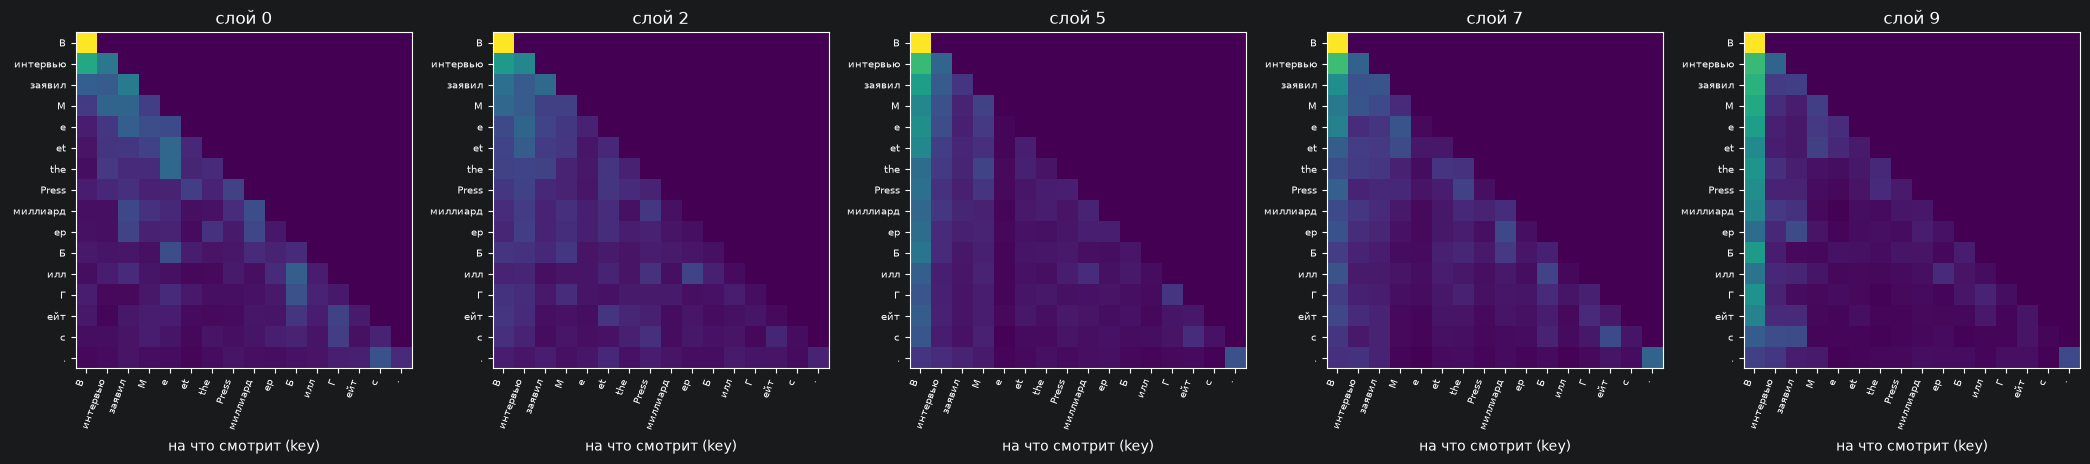

In [52]:
_ = plot_attention_maps(model,
                        "В интервью заявил Meet the Press миллиардер Билл Гейтс.")

Если бы внимание определялось смыслом первого слова, столбец у левого края должен был бы ослабеть, а часть внимания переместиться на слова «миллиардер Билл Гейтс» в конце предложения. Однако на картах столбец у левого края сохраняется, хотя теперь первым стоит предлог «В», не несущий смысловой нагрузки. Значит, дело не в значении слова, а в его позиции.

С другой стороны перестановка не вполне убедительна: предлог «В» тоже может играть особую роль в начале предложения, а само предложение короткое. Поэтому усилим проверку двумя способами: **удлиним текст** и поставим на первое место слово, не связанное с ним по смыслу - «Арбуз».

In [53]:
long_text = "Арбуз. Искусственный интеллект стремительно становится частью повседневной жизни, а разработчики и компании продолжают расширять возможности современных нейросетей. Новые системы уже умеют работать с текстом, изображениями, звуком и видео, помогать пользователям анализировать большие объёмы информации и выполнять задачи, которые раньше требовали значительного количества времени. Одним из главных направлений развития ИИ остаётся повышение качества ответов и способности систем понимать сложные запросы. Современные модели всё чаще используются в образовании, программировании, маркетинге, медицине, промышленности и других сферах. Компании внедряют такие технологии не только для автоматизации рутинных операций, но и для поддержки сотрудников при принятии решений. При этом распространение искусственного интеллекта сопровождается дискуссиями о возможных рисках. Эксперты обращают внимание на проблему недостоверной информации, вопросы конфиденциальности, авторских прав и изменения требований к специалистам на рынке труда. Отдельное внимание уделяется необходимости устанавливать понятные правила использования ИИ и контролировать применение технологии в чувствительных областях. нейросети более точными, безопасными и удобными для пользователей. Ожидается, что в ближайшие годы искусственный интеллект продолжит активно развиваться и будет использоваться в ещё большем количестве повседневных и профессиональных задач. Таким образом, ИИ постепенно перестаёт быть исключительно экспериментальной технологией и превращается в универсальный инструмент, влияние которого становится заметным практически во всех сферах жизни."


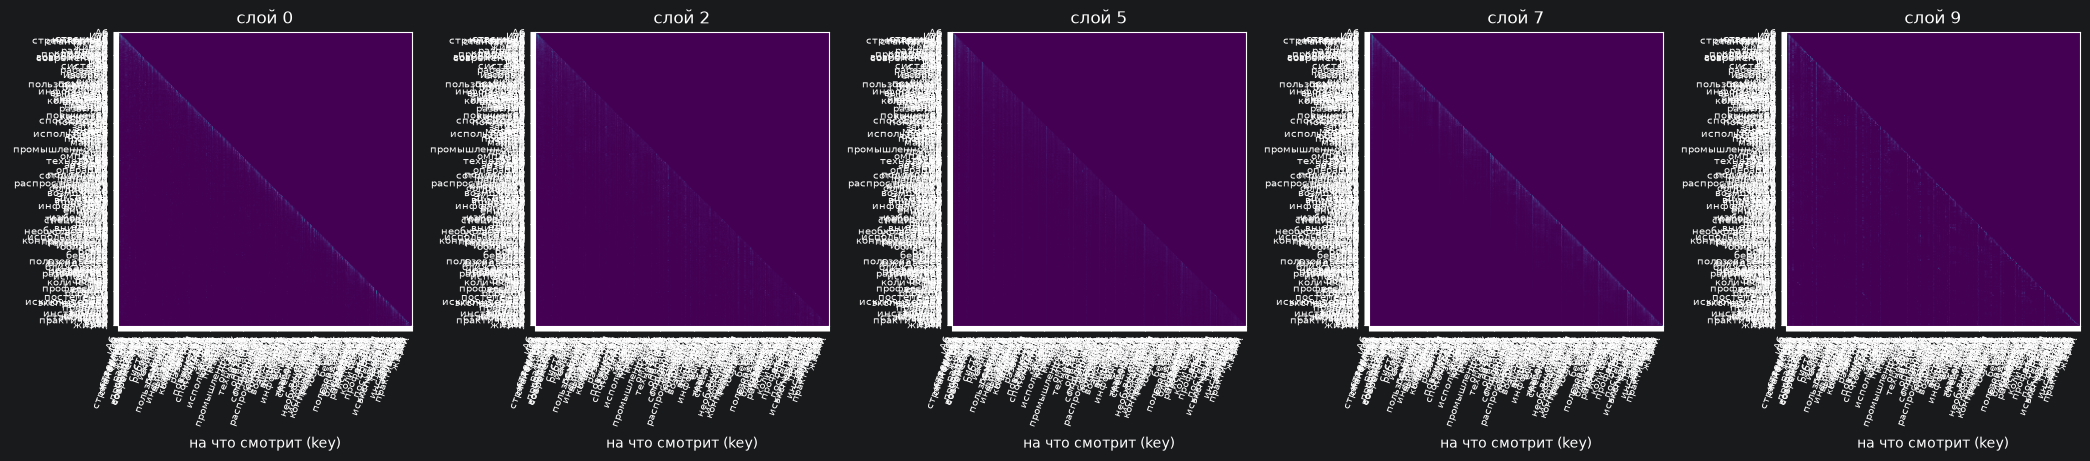

In [54]:
mean_att = plot_attention_maps(model, long_text)



Если бы внимание определялось смыслом первого слова, то слово «Арбуз», не имеющее отношения к тексту, не должно было бы привлекать внимание остальных токенов. Однако столбец у левого края снова сохраняется и остается заметным на протяжении всего длинного предложения. Значит, внимание к первому токену определяется его позицией, а не значением слова: оно выступает в роли опорной точки, видимой всем последующим токенам, и модель использует ее, когда ни один из токенов контекста не требует особого внимания.

### Attention sink

Описанное явление называют attention sink («сток внимания»): значительная часть весов внимания направляется на самые первые токены последовательности, независимо от того, что это за слова.

Почему так происходит. Веса внимания для каждого токена нормируются: их сумма всегда равна единице. Токен не может «ничего не выбрать»: вес обязательно нужно куда-то направить, даже если в контексте нет информации, которая ему сейчас нужна. Модели нужен способ «сбросить» лишний вес так, чтобы он не исказил результат. Первый токен подходит для этого лучше остальных. Модель в процессе обучения учится использовать его как постоянную «пустую» точку. Считается, что вклад такого токена в итоговое представление невелик, поэтому большой вес на нем почти ничего не меняет в результате. Смысл самого слова при этом не важен, что подтверждают наши эксперименты с перестановкой слов и словом «Арбуз».



### Разреженность внимания

Обратимся еще раз к карте внимания для длинного текста. Если не обращать внимания на столбец у левого края, видно, что основная часть матрицы остается темной: ненулевой вес имеет лишь небольшое число ячеек. В каждой строке сильное внимание сосредоточено на нескольких позициях: на ближайших соседях (диагональная полоса, прилегающая к главной диагонали) и на первых токенах. Остальные ячейки допустимой области практически «пустуют».

Стандартный механизм внимания вычисляет вес для каждой допустимой пары токенов, то есть тратит время и память на всю матрицу. Однако значимую часть результата определяет лишь малая доля этих пар, а вклад остальных пренебрежимо мал. Чем длиннее последовательность, тем сильнее проявляется этот эффект: число пар растет как $T^2$, а число существенных связей у каждого токена остается примерно одним и тем же. Следовательно, на длинных текстах основная часть вычислений тратится впустую.


## 3.2 Разреженное внимание: скользящее окно

Наблюдения по картам внимания подсказывают простую схему: оставить каждому токену только тех, кого он действительно использует, то есть ближайших соседей. В схеме скользящего окна (sliding window attention) токен $i$ видит только последние $W$ токенов, от $i - W + 1$ до $i$ включительно. Вместо полной треугольной матрицы получается узкая полоса вдоль диагонали, а число вычисляемых пар растет пропорционально $T \cdot W$, а не $T^2$. Для длинных последовательностей разница существенна: при $T = 2048$ и $W = 36$ полоса содержит примерно в 28 раз меньше пар, чем полная матрица .


### Как устроена оптимизация

Текст нарезают на одинаковые куски по $W$ токенов. Например, при $W = 4$:

```
[ t1 t2 t3 t4 ] [ t5 t6 t7 t8 ] [ t9 t10 t11 t12 ]
   чанк 1           чанк 2            чанк 3
```

Возьмем t9 (первый токен чанка 3): ему нужны $W = 4$ последних токена, t6-t9. Токены t6-t8 лежат в чанке 2, сам t9 в чанке 3. Возьмем t12 (последний токен чанка): ему нужны t9-t12, и все они в чанке 3. Окно любого токена не уходит дальше предыдущего чанка, поэтому чанк 1 для токенов чанка 3 не нужен.

 Для всех токенов чанка можно взять один общий набор из $2W$ ключей: $W$ ключей предыдущего чанка плюс $W$ ключей текущего (для чанка 3 это t5-t12). Из него каждый токен использует только свои $W$ ключей, остальные закрывает маска: например, t9 использует t6-t9, а t5 (слишком далеко) и t10-t12 (будущее) закрыты. Вместо одной матрицы $T \times T$ получается $T / W$ небольших матриц размером $W \times 2W$, по одной на чанк.

Сравнение на примере `■` - пара нужна, `·` - не нужна или закрыта маской.

Обычное внимание: полная матрица $12 \times 12$, вычисляются все 144 пары, нужны только 42.

```
        1  2  3  4  | 5  6  7  8  | 9  10 11 12
t1      ■  ·  ·  ·  | ·  ·  ·  ·  | ·  ·  ·  ·
t2      ■  ■  ·  ·  | ·  ·  ·  ·  | ·  ·  ·  ·
t3      ■  ■  ■  ·  | ·  ·  ·  ·  | ·  ·  ·  ·
t4      ■  ■  ■  ■  | ·  ·  ·  ·  | ·  ·  ·  ·
t5      ·  ■  ■  ■  | ■  ·  ·  ·  | ·  ·  ·  ·
t6      ·  ·  ■  ■  | ■  ■  ·  ·  | ·  ·  ·  ·
t7      ·  ·  ·  ■  | ■  ■  ■  ·  | ·  ·  ·  ·
t8      ·  ·  ·  ·  | ■  ■  ■  ■  | ·  ·  ·  ·
t9      ·  ·  ·  ·  | ·  ■  ■  ■  | ■  ·  ·  ·
t10     ·  ·  ·  ·  | ·  ·  ■  ■  | ■  ■  ·  ·
t11     ·  ·  ·  ·  | ·  ·  ·  ■  | ■  ■  ■  ·
t12     ·  ·  ·  ·  | ·  ·  ·  ·  | ■  ■  ■  ■
```

Вместо одной большой матрицы строятся три маленькие, по одной на чанк. Размер каждой $4 \times 8$: четыре запроса чанка против восьми ключей (предыдущий чанк плюс текущий). Вычисляются 96 пар, и среди них те же самые 42 нужные:

```
Чанк 1: ключи [нет предыдущего | t1–t4]
        –  –  –  –  | 1  2  3  4
t1      –  –  –  –  | ■  ·  ·  ·
t2      –  –  –  –  | ■  ■  ·  ·
t3      –  –  –  –  | ■  ■  ■  ·
t4      –  –  –  –  | ■  ■  ■  ■

Чанк 2: ключи [t1–t4 | t5–t8]
        1  2  3  4  | 5  6  7  8
t5      ·  ■  ■  ■  | ■  ·  ·  ·
t6      ·  ·  ■  ■  | ■  ■  ·  ·
t7      ·  ·  ·  ■  | ■  ■  ■  ·
t8      ·  ·  ·  ·  | ■  ■  ■  ■

Чанк 3: ключи [t5–t8 | t9–t12]
        5  6  7  8  | 9  10 11 12
t9      ·  ■  ■  ■  | ■  ·  ·  ·
t10     ·  ·  ■  ■  | ■  ■  ·  ·
t11     ·  ·  ·  ■  | ■  ■  ■  ·
t12     ·  ·  ·  ·  | ■  ■  ■  ■
```

In [55]:
def sparse_causal_mask(seq_len, window, device):
    window = int(window)

    i = torch.arange(seq_len, device=device).unsqueeze(1)
    j = torch.arange(seq_len, device=device).unsqueeze(0)

    future = j > i
    too_far = j < (i - window + 1)

    return future | too_far


class SlidingWindowMHA(MultiHeadAttention):
    """Каузальное локальное внимание: токен i видит токены [i-W+1, i].
    Веса те же, что у MultiHeadAttention; меняется только вычисление."""

    def __init__(self, d_model: int, n_heads: int, window: int = 32):
        super().__init__(d_model, n_heads)
        self.window = int(window)
        self._mask_cache = {}  # не буфер, в state_dict не попадает

    def _chunk_mask(self, n_chunks, device):
        key = (n_chunks, self.window, str(device))
        m = self._mask_cache.get(key)
        if m is None:
            C = self.window
            a = torch.arange(C, device=device).unsqueeze(1)  # позиция запроса в чанке
            b = torch.arange(2 * C, device=device).unsqueeze(0)  # позиция ключа в [prev | cur]
            m = ((b > a) & (b <= a + C))  # True = можно смотреть
            m = m.unsqueeze(0).repeat(n_chunks, 1, 1)
            m[0, :, :C] = False  # у первого чанка нет предыдущего
            self._mask_cache[key] = m.unsqueeze(1)  # (nc, 1, C, 2C)
        return self._mask_cache[key]

    def forward(self, x, mask=None):
        if mask is not None:
            return super().forward(x, mask=mask)
        B, N, _ = x.shape
        C, H, dk = self.window, self.n_heads, self.d_k
        pad = (-N) % C

        Q = self._split_heads(self.q_proj(x))
        K = self._split_heads(self.k_proj(x))
        V = self._split_heads(self.v_proj(x))
        if pad:
            Q, K, V = [F.pad(t, (0, 0, 0, pad)) for t in (Q, K, V)]
        nc = (N + pad) // C

        Q = Q.view(B, H, nc, C, dk)
        K = K.view(B, H, nc, C, dk)
        V = V.view(B, H, nc, C, dk)
        K = torch.cat([F.pad(K, (0, 0, 0, 0, 1, 0))[:, :, :-1], K], dim=3)
        V = torch.cat([F.pad(V, (0, 0, 0, 0, 1, 0))[:, :, :-1], V], dim=3)

        def fold(t):
            return t.transpose(1, 2).reshape(B * nc, H, t.size(3), dk)

        m = self._chunk_mask(nc, x.device)[None].expand(B, -1, -1, -1, -1).reshape(B * nc, 1, C, 2 * C)
        out = F.scaled_dot_product_attention(fold(Q), fold(K), fold(V), attn_mask=m)

        out = out.view(B, nc, H, C, dk).transpose(1, 2).reshape(B, H, nc * C, dk)[:, :, :N]
        return self.out_proj(self._merge_heads(out)), None


class TLMCS(TransformerLM):
    def __init__(self, tokenizer, d_model=256, n_heads=4, n_layers=4,
                 d_ff=1024, max_len=512, dropout=0.1, window=36):
        super().__init__(tokenizer, d_model, n_heads, n_layers, d_ff, max_len, dropout)
        self.window = window
        for block in self.blocks:  # подмена только внимания
            block.attn = SlidingWindowMHA(d_model, n_heads, window)

    def forward(self, x, return_attn=False, return_hidden_at=None, **sampling_kwargs):
        mask = None
        if return_attn:  # плотная маска только когда нужны карты
            mask = sparse_causal_mask(x.size(1), self.window, x.device)
        h = self.pos_encoding(self.embedding(x))
        attn_maps, hidden_snapshot = [], None
        for i, block in enumerate(self.blocks):
            h, attn_w = block(h, mask=mask)
            if return_attn:
                attn_maps.append(attn_w)
            if return_hidden_at is not None and i == return_hidden_at:
                hidden_snapshot = h.clone()
        logits = self.head(self.ln_f(h))
        if return_attn or return_hidden_at is not None:
            return logits, attn_maps, hidden_snapshot
        return logits, None


### Предобученная модель с окном

Чтобы можно было сравнить схемы внимания на практике, для этого раздела для вас была обучена модель того же типа, что и в блоке 2,
но с разреженным вниманием: скользящим окном длиной $W = 32$. Каждый токен в ней видит только 32 последних токена, включая себя. Модель загружается так же, как и предыдущая, через `extract_model`, а затем строится как экземпляр `TLMCS` с параметром `window`, равным 32.

In [56]:
config, state_dict, tokenizer = extract_model('model_cs.tar.xz')
config


{'train_seq_len': 2048,
 'emb_dim': 384,
 'hidden_dim': 1536,
 'num_layers': 10,
 'n_heads': 6}

In [57]:
model_t_cs = TLMCS(
    d_model=int(config["emb_dim"]),
    n_layers=int(config["num_layers"]),
    n_heads=int(config.get("n_heads", 4)),
    d_ff=int(config["hidden_dim"]),
    max_len=int(config['train_seq_len']),
    tokenizer=tokenizer,
)
model_t_cs.load_state_dict(state_dict)
model_t_cs.eval()

TLMCS(
  (embedding): Embedding(16000, 384)
  (pos_encoding): PositionalEncoding()
  (blocks): ModuleList(
    (0-9): 10 x DecoderBlock(
      (ln1): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): SlidingWindowMHA(
        (q_proj): Linear(in_features=384, out_features=384, bias=True)
        (k_proj): Linear(in_features=384, out_features=384, bias=True)
        (v_proj): Linear(in_features=384, out_features=384, bias=True)
        (out_proj): Linear(in_features=384, out_features=384, bias=True)
      )
      (ln2): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=True)
      (ff): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=384, out_features=1536, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=1536, out_features=384, bias=True)
        )
      )
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (ln_f): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=True)
 

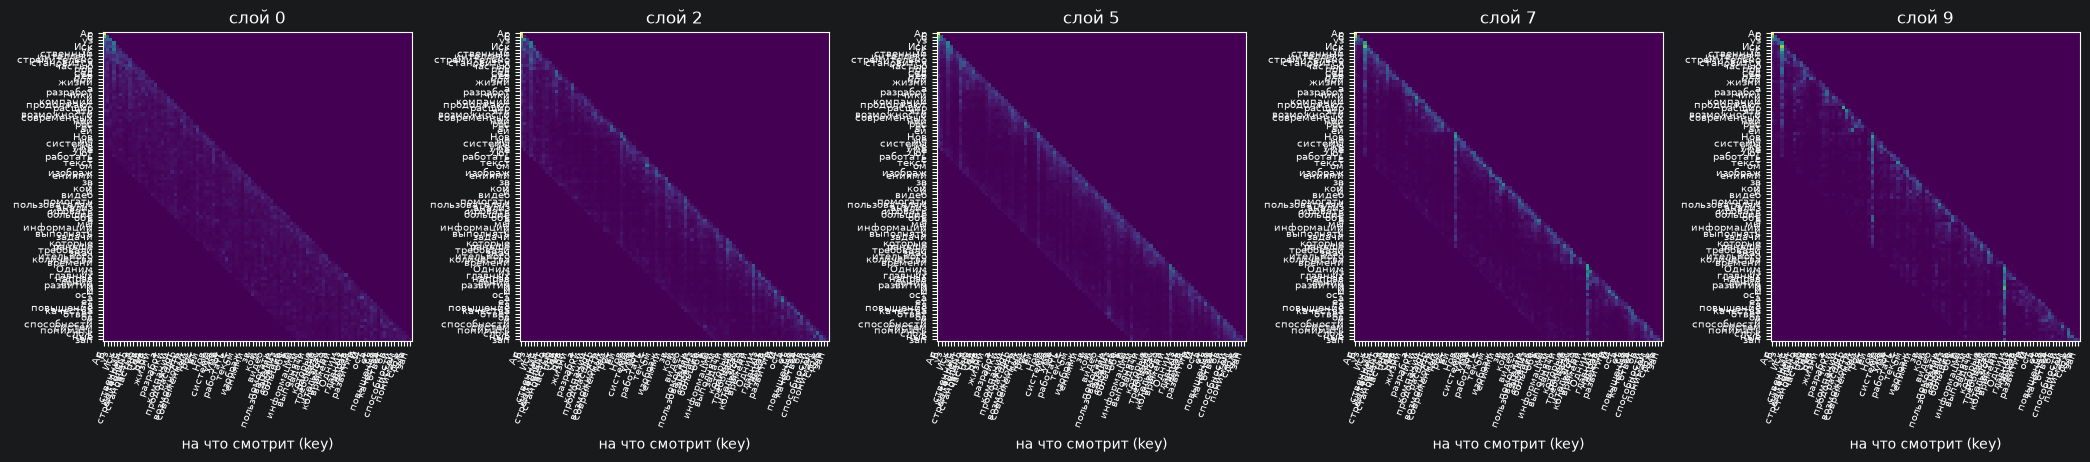

In [58]:
mean_att = plot_attention_maps(model_t_cs, long_text[:500])

Построим карты внимания для модели с окном $W = 32$ тем же способом, что и для полной модели. Картина меняется: вместо одного яркого столбца у левого края мы видим **повторяющиеся яркие столбцы в начале каждого чанка**. Токены каждого чанка обращаются к первому токену именно своего чанка.

В полной модели первый токен служит опорной точкой, потому что он виден всем последующим токенам. В модели с окном такой токен недоступен: через 32 позиции первый токен выходит за границу окна, и обращаться к нему уже нельзя. Но потребность в опорной точке остается, так как веса внимания по-прежнему должны суммироваться в единицу и их нужно куда-то направлять. Модель решает эту задачу сама: создает опорную точку заново в начале каждого чанка.


In [59]:
model = model.cuda()
model_t_cs = model_t_cs.cuda()
part_text = long_text[:400]
gen = LanguageModelGenerator(TransformerStepper(model))
print(part_text + ':')
print(gen.generate(part_text)[len(part_text):])
print('------')
gen = LanguageModelGenerator(TransformerStepper(model_t_cs))
print(gen.generate(part_text)[len(part_text):])

Арбуз. Искусственный интеллект стремительно становится частью повседневной жизни, а разработчики и компании продолжают расширять возможности современных нейросетей. Новые системы уже умеют работать с текстом, изображениями, звуком и видео, помогать пользователям анализировать большие объёмы информации и выполнять задачи, которые раньше требовали значительного количества времени. Одним из главных н:
юансов в сфере интернета является то, что в современном мире не только не только не работает, но и работает, например, в сфере интернета. В частности, в сети можно найти и другие возможности для создания новых технологий, которые позволят создать новые технологии
------
оваций стал «умный» телевизор, который можно использовать для создания собственного контента. В частности, в приложении будет размещен текст, который будет доступен для пользователей, которые смогут увидеть его на экране телевизора. В частности, в прилож


Задание. Сравните две модели: с полным вниманием (`model`) и со скользящим окном (`model_t_cs`, $W = 32$). Для этого постройте два графика, где по оси $x$ откладывается длина контекста (длина входной последовательности), а каждая модель представлена отдельной линией (графики 1 и 2).

Выберите набор длин, кратных размеру окна, от небольших значений до максимальной длины контекста моделей (например, 64, 128, 256, 512, 1024, 2048).

График 1.  Для каждой длины замерьте время обработки датасета каждой моделью.

При замере учтите следующее:
- модель должна быть в режиме `eval`, вычисления выполняются под `torch.no_grad()`, а `return_attn` не используется: иначе внимание считается в плотном режиме, и сравнение теряет смысл;
- размер батча одинаков для всех длин и моделей;
- перед замером выполните несколько «прогревочных» запусков, а время измеряйте после вызова `torch.cuda.synchronize()` (на GPU вычисления асинхронны, и без синхронизации замер покажет не время вычислений);
- повторите замер несколько раз и возьмите медиану, чтобы сгладить случайные колебания.


График 2. Для каждой длины вычислите среднюю кросс-энтропию на валидационной выборке для обеих моделей. Пример вычисления для одной длины:

```python
criterion = nn.CrossEntropyLoss(ignore_index=model.tokenizer.pad_id)
seq_len = 512
val_ds = SlidingWindowDataset(val_docs, tokenizer, seq_len)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, drop_last=True)
print(evaluate(model_t_cs, val_loader, criterion))
print(evaluate(model, val_loader, criterion))
```

Повторите его для всех выбранных длин. Используйте одну и ту же валидационную выборку и один и тот же `criterion` для обеих моделей.

Сгенерируйте продолжения одного и тоже обеими моделями и сравните тексты.

```python
gen_full = LanguageModelGenerator(TransformerStepper(model))
gen_win = LanguageModelGenerator(TransformerStepper(model_t_cs))

print(gen_full.generate(prompt, max_new_tokens=300))
print(gen_win.generate(prompt, max_new_tokens=300))
```


Обратите внимание на связность текста, сохранение темы и героев по мере удаления от затравки, наличие повторов и обрывов смысла. Кроме того, замерьте время генерации одного и того же числа токенов каждой моделью и сопоставьте его с графиком 1.

Выводы. Ответьте письменно на вопросы:
1. Как растет время обработки у каждой модели при увеличении длины? Чем объясняется различие в характере роста?
2. При какой длине выигрыш от скользящего окна становится заметным? Как он меняется дальше?
3. Насколько хуже модель с окном по кросс-энтропии и как этот разрыв зависит от длины контекста?
4. Чем отличаются тексты, сгенерированные двумя моделями? Проявляется ли ограниченность окна в генерации, и согласуется ли это с результатами графика 2?

Для самостоятельного изучения. (не влияет на баллы) Скользящее окно ускоряет вычисления, но ценой потери части контекста: токены, вышедшие за границу окна, напрямую недоступны. В разделе про карты внимания мы увидели, что модели используют первые токены как опорную точку (attention sink), а в модели с окном они вынуждены создавать такие точки заново. Если хотите разобраться в вопросе подробнее, найдите информацию о том, как это явление используют на практике для работы с длинными последовательностями. Вот что стоит выяснить:
- что происходит с качеством генерации, когда первые токены выходят из окна;
- что предлагается сделать, чтобы этого избежать, и почему это помогает;
- чего этот прием не решает: какую информацию модель по-прежнему не может использовать.
